# Gold Daily Volatility Forecasting

This notebook adapts the workflow from the BTC **Volatility Forecasting** project to daily Gold Futures data from Yahoo Finance.

**Asset:** COMEX Gold Futures (`GC=F`)  
**Interval:** 1 day  
**Target:** next trading day's high-low range, normalized by the recent 20-day average range.

Models:
- PyTorch neural network
- XGBoost
- Ridge regression

The goal is to forecast a volatility proxy, not the direction of the gold price.

In [15]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 1. Download daily gold data from Yahoo Finance

Yahoo Finance ticker `GC=F` represents COMEX Gold Futures. The download is saved as a CSV so the same historical dataset can be reused without downloading it every time.

In [16]:
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
CSV_PATH = DATA_DIR / "gold_daily.csv"

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH, parse_dates=["date"], index_col="date")
    print("Loaded existing CSV:", CSV_PATH)
else:
    raw = yf.download(
        "GC=F",
        start="2000-01-01",
        interval="1d",
        auto_adjust=False,
        progress=False
    )

    if raw.empty:
        raise RuntimeError("Yahoo Finance returned no data. Check your internet connection or ticker.")

    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)

    raw.columns = [str(c).lower().replace(" ", "_") for c in raw.columns]
    raw.index.name = "date"
    df = raw.copy()
    df.to_csv(CSV_PATH)
    print("Downloaded and saved:", CSV_PATH)

print("Rows:", len(df))
print("First date:", df.index.min())
print("Last date:", df.index.max())
display(df.head())

Loaded existing CSV: data\gold_daily.csv
Rows: 6585
First date: 2000-08-30 00:00:00
Last date: 2026-11-24 00:00:00


,adj_close,close,high,low,open,volume
date,,,,,,
2000-08-30,273.899994,273.899994,273.899994,273.899994,273.899994,0
2000-08-31,278.299988,278.299988,278.299988,274.799988,274.799988,0
2000-09-01,277.000000,277.000000,277.000000,277.000000,277.000000,0
2000-09-05,275.799988,275.799988,275.799988,275.799988,275.799988,2
2000-09-06,274.200012,274.200012,274.200012,274.200012,274.200012,0


## 2. Clean the data

In [17]:
df = df.copy()
df.index = pd.to_datetime(df.index)
df = df[~df.index.duplicated(keep="first")].sort_index()

required = ["open", "high", "low", "close", "volume"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required Yahoo Finance columns: {missing}")

for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["open", "high", "low", "close"])
df = df[(df["open"] > 0) & (df["high"] > 0) & (df["low"] > 0) & (df["close"] > 0)]

print("Clean rows:", len(df))
display(df[required].describe())

Clean rows: 6585


,open,high,low,close,volume
count,6585.000000,6585.000000,6585.000000,6585.000000,6585.000000
mean,1364.453045,1373.828838,1354.524009,1364.342536,51854.190433
std,931.402797,942.442919,919.685900,931.280228,92767.520892
min,255.000000,256.100006,255.000000,255.100006,0.000000
25%,661.500000,663.700012,660.000000,661.500000,29.000000
50%,1262.500000,1269.000000,1256.599976,1262.800049,202.000000
75%,1733.199951,1744.699951,1721.599976,1731.699951,98745.000000
max,5415.700195,5586.200195,5272.899902,5318.399902,570055.000000


## 3. Feature engineering

Only past and current-day information is used to create features. The target is shifted one trading day into the future.

In [18]:
df["daily_return"] = df["close"].pct_change() * 100
df["intraday_return"] = (df["close"] - df["open"]) / df["open"] * 100
df["daily_range"] = (df["high"] - df["low"]) / df["low"] * 100
df["close_return"] = np.log(df["close"] / df["close"].shift(1)) * 100

# Rolling volatility and range
for window in [5, 10, 20, 60]:
    df[f"volatility_{window}"] = df["close_return"].rolling(window).std()
    df[f"range_ma_{window}"] = df["daily_range"].rolling(window).mean()

# Volume features (Yahoo may report zero or missing volume for some futures sessions)
df["volume"] = df["volume"].fillna(0)
df["volume_change"] = df["volume"].pct_change().replace([np.inf, -np.inf], np.nan)
df["volume_ma_20"] = df["volume"].rolling(20).mean()
df["volume_ratio"] = df["volume"] / (df["volume_ma_20"] + 1e-8)
df["log_volume"] = np.log1p(df["volume"])

# Moving averages and distance from trend
for window in [5, 20, 50, 100]:
    df[f"ma_{window}"] = df["close"].rolling(window).mean()
    df[f"distance_ma_{window}"] = (df["close"] - df[f"ma_{window}"]) / (df[f"ma_{window}"] + 1e-8)

# Lagged returns and ranges
for lag in [1, 2, 3, 5, 10]:
    df[f"return_lag_{lag}"] = df["close_return"].shift(lag)
    df[f"range_lag_{lag}"] = df["daily_range"].shift(lag)

# Market regime and drawdown
df["volatility_regime"] = df["volatility_5"] / (df["volatility_20"] + 1e-8)
df["range_vs_ma_20"] = df["daily_range"] / (df["range_ma_20"] + 1e-8)
df["rolling_high_60"] = df["close"].rolling(60).max()
df["drawdown_60"] = (df["close"] - df["rolling_high_60"]) / (df["rolling_high_60"] + 1e-8)
df["return_skew_20"] = df["close_return"].rolling(20).skew()

# Day-of-week seasonality
day_of_week = df.index.dayofweek
df["weekday_sin"] = np.sin(2 * np.pi * day_of_week / 5)
df["weekday_cos"] = np.cos(2 * np.pi * day_of_week / 5)

# Predict the next trading day's range, normalized by the recent average range
df["next_day_range"] = df["daily_range"].shift(-1)
df["target"] = df["next_day_range"] / (df["range_ma_20"] + 1e-8)

display(df.tail())

,adj_close,close,high,low,open,volume,daily_return,intraday_return,daily_range,close_return,...,range_lag_10,volatility_regime,range_vs_ma_20,rolling_high_60,drawdown_60,return_skew_20,weekday_sin,weekday_cos,next_day_range,target
date,,,,,,,,,,,,,,,,,,,,,
2026-11-18,3741.899902,3741.899902,3859.300049,3721.800049,3855.199951,244253,-3.164951,-2.938889,3.694449,-3.216118,...,3.894914,0.953618,1.548883,4664.000000,-0.197706,0.179725,0.587785,-0.809017,3.836378,1.608387
2026-11-19,3685.500000,3685.500000,3759.500000,3620.600098,3730.300049,203702,-1.507253,-1.200977,3.836378,-1.518728,...,2.183423,0.829914,1.585850,4664.000000,-0.209798,0.166819,-0.587785,-0.809017,3.859665,1.595476
2026-11-20,3515.399902,3515.399902,3638.100098,3502.899902,3633.800049,336479,-4.615387,-3.258301,3.859665,-4.725291,...,2.009866,1.022666,1.522232,4539.899902,-0.225666,-0.203036,-0.951057,0.309017,3.904511,1.539919
2026-11-23,3651.399902,3651.399902,3691.000000,3552.300049,3570.500000,336479,3.868692,2.265786,3.904511,3.795734,...,2.343389,1.530741,1.465531,4539.899902,-0.195709,0.114733,0.000000,1.000000,3.353574,1.258741
2026-11-24,3562.399902,3562.399902,3676.699951,3557.399902,3636.399902,194350,-2.437421,-2.034980,3.353574,-2.467618,...,3.367493,1.493934,1.226305,4539.899902,-0.215313,0.311647,0.951057,0.309017,NaN,NaN


## 4. Select features and prepare the dataset

In [19]:
feature_cols = [
    "daily_return", "intraday_return", "daily_range", "close_return",
    "volatility_5", "volatility_10", "volatility_20", "volatility_60",
    "range_ma_5", "range_ma_10", "range_ma_20", "range_ma_60",
    "volume_change", "volume_ratio", "log_volume",
    "distance_ma_5", "distance_ma_20", "distance_ma_50", "distance_ma_100",
    "return_lag_1", "return_lag_2", "return_lag_3", "return_lag_5", "return_lag_10",
    "range_lag_1", "range_lag_2", "range_lag_3", "range_lag_5", "range_lag_10",
    "volatility_regime", "range_vs_ma_20", "drawdown_60", "return_skew_20",
    "weekday_sin", "weekday_cos"
]

needed = feature_cols + ["target"]
df_clean = df.replace([np.inf, -np.inf], np.nan)
df_clean = df_clean.dropna(subset=needed).copy()

print("Total usable rows:", len(df_clean))
print("Number of features:", len(feature_cols))
print("First usable date:", df_clean.index.min())
print("Last usable date:", df_clean.index.max())

if len(df_clean) < 500:
    raise ValueError("Not enough historical rows to train and evaluate the models.")

Total usable rows: 6117
Number of features: 35
First usable date: 2001-01-30 00:00:00
Last usable date: 2026-11-23 00:00:00


## 5. Chronological train/test split

The last 20% of observations are kept for testing. The scaler is fitted only on the training data to avoid leaking information from the test period.

In [20]:
split_point = int(len(df_clean) * 0.8)

X = df_clean[feature_cols].values.astype("float32")
y = df_clean["target"].values.astype("float32")

X_train_raw, X_test_raw = X[:split_point], X[split_point:]
y_train, y_test = y[:split_point], y[split_point:]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype("float32")
X_test = scaler.transform(X_test_raw).astype("float32")

train_dates = df_clean.index[:split_point]
test_dates = df_clean.index[split_point:]

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("Training period:", train_dates.min(), "to", train_dates.max())
print("Testing period: ", test_dates.min(), "to", test_dates.max())

X_train: (4893, 35)
X_test:  (1224, 35)
Training period: 2001-01-30 00:00:00 to 2021-12-30 00:00:00
Testing period:  2021-12-31 00:00:00 to 2026-11-23 00:00:00


## 6. PyTorch neural network

In [21]:
model = nn.Sequential(
    nn.Linear(len(feature_cols), 32),
    nn.ReLU(),
    nn.Linear(32, 1),
    nn.Softplus()
).to(DEVICE)

print(model)

X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

loader = DataLoader(
    TensorDataset(X_tensor, y_tensor),
    batch_size=128,
    shuffle=True
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 30
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        predictions = model(xb)
        loss = loss_fn(predictions, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1:02d}/{EPOCHS} | Loss: {total_loss / len(loader):.6f}")

Sequential(
  (0): Linear(in_features=35, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
  (3): Softplus(beta=1.0, threshold=20.0)
)
Epoch 05/30 | Loss: 24863415757077.675781
Epoch 10/30 | Loss: 24863408390175.218750
Epoch 15/30 | Loss: 24863401776184.550781
Epoch 20/30 | Loss: 24863389731287.015625
Epoch 25/30 | Loss: 24863376019699.402344
Epoch 30/30 | Loss: 24863359834955.281250


## 7. Evaluate the neural network

In [22]:
model.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(DEVICE)
    nn_predictions = model(X_test_tensor).cpu().numpy().ravel()

def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

naive_predictions = np.full(len(y_test), y_train.mean())

results = [
    evaluate_model("Neural Network", y_test, nn_predictions),
    evaluate_model("Naive mean baseline", y_test, naive_predictions)
]

pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Neural Network,11.652025,21.917826,-1.907534e+03
1,Naive mean baseline,131898.765625,131898.751958,-6.911722e+10


## 8. XGBoost model

In [23]:
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=SEED
)

xgb_model.fit(X_train_raw, y_train)
xgb_predictions = np.maximum(xgb_model.predict(X_test_raw), 0)

results.append(evaluate_model("XGBoost", y_test, xgb_predictions))
pd.DataFrame(results).sort_values("RMSE")

,Model,MAE,RMSE,R2
2,XGBoost,3.574720,3.605774,-5.065376e+01
0,Neural Network,11.652025,21.917826,-1.907534e+03
1,Naive mean baseline,131898.765625,131898.751958,-6.911722e+10


## 9. Ridge regression baseline

In [24]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_predictions = np.maximum(ridge_model.predict(X_test), 0)

results.append(evaluate_model("Ridge", y_test, ridge_predictions))
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

,Model,MAE,RMSE,R2
0,XGBoost,3.574720,3.605774,-5.065376e+01
1,Neural Network,11.652025,21.917826,-1.907534e+03
2,Naive mean baseline,131898.765625,131898.751958,-6.911722e+10
3,Ridge,57246.089844,155422.738311,-9.596967e+10


## 10. Compare predictions on the test period

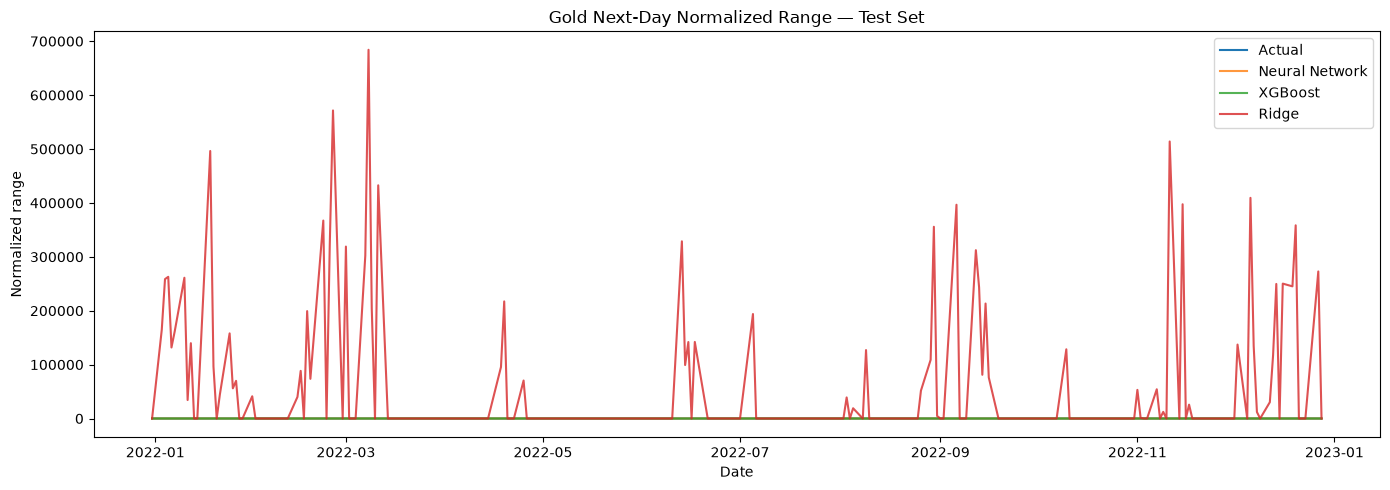

In [25]:
comparison = pd.DataFrame({
    "actual": y_test,
    "neural_network": nn_predictions,
    "xgboost": xgb_predictions,
    "ridge": ridge_predictions
}, index=test_dates)

n = min(250, len(comparison))
plt.figure(figsize=(14, 5))
plt.plot(comparison.index[:n], comparison["actual"].iloc[:n], label="Actual", linewidth=1.5)
plt.plot(comparison.index[:n], comparison["neural_network"].iloc[:n], label="Neural Network", alpha=0.8)
plt.plot(comparison.index[:n], comparison["xgboost"].iloc[:n], label="XGBoost", alpha=0.8)
plt.plot(comparison.index[:n], comparison["ridge"].iloc[:n], label="Ridge", alpha=0.8)
plt.title("Gold Next-Day Normalized Range — Test Set")
plt.xlabel("Date")
plt.ylabel("Normalized range")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Actual vs predicted

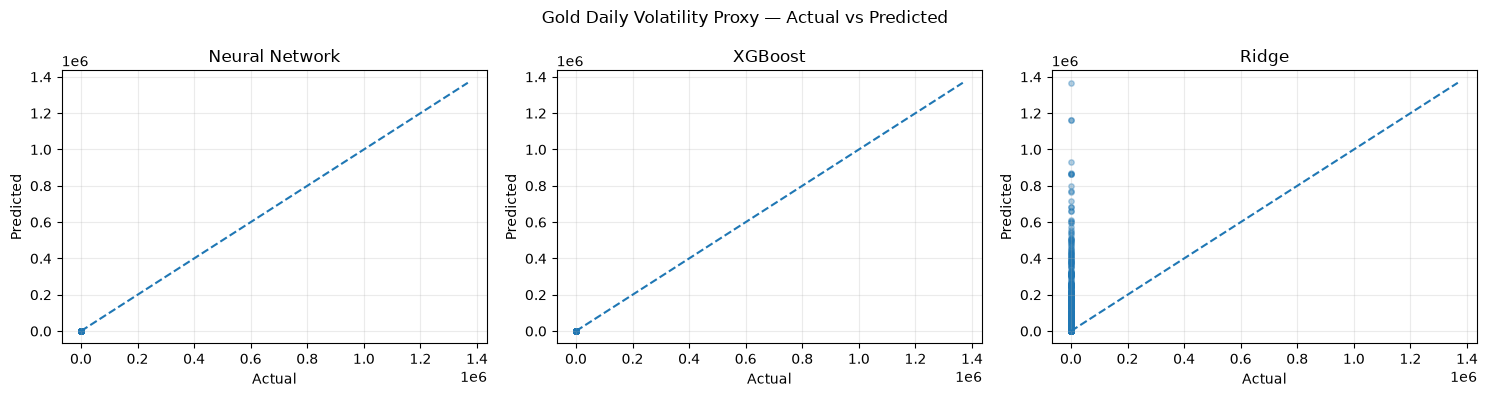

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
models = [
    ("Neural Network", nn_predictions),
    ("XGBoost", xgb_predictions),
    ("Ridge", ridge_predictions)
]

low = min(y_test.min(), nn_predictions.min(), xgb_predictions.min(), ridge_predictions.min())
high = max(y_test.max(), nn_predictions.max(), xgb_predictions.max(), ridge_predictions.max())

for ax, (name, prediction) in zip(axes, models):
    ax.scatter(y_test, prediction, alpha=0.35, s=15)
    ax.plot([low, high], [low, high], linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(alpha=0.25)

fig.suptitle("Gold Daily Volatility Proxy — Actual vs Predicted")
plt.tight_layout()
plt.show()

## 12. Feature importance

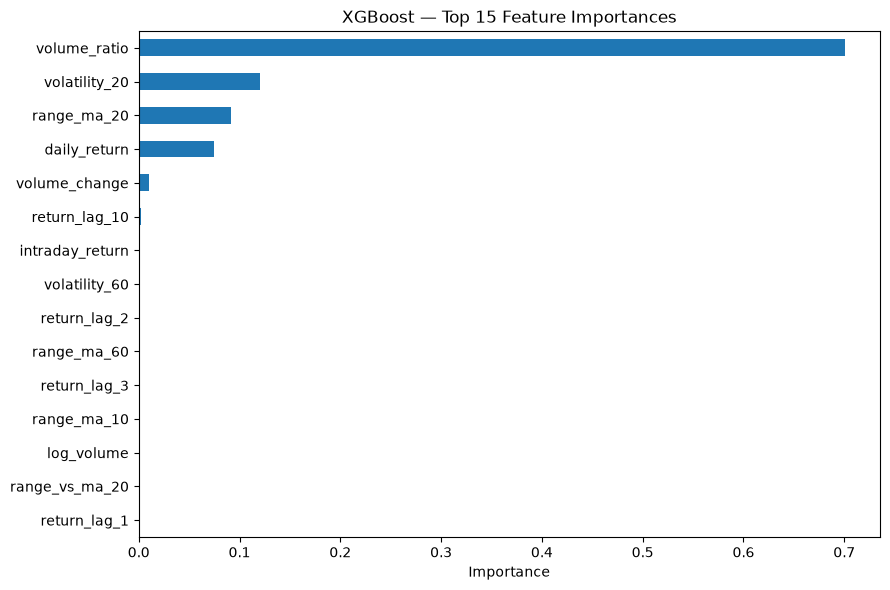

In [27]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=True).tail(15)

plt.figure(figsize=(9, 6))
importance.plot(kind="barh")
plt.title("XGBoost — Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 13. Save test predictions

In [28]:
OUTPUT_PATH = DATA_DIR / "gold_test_predictions.csv"
comparison.to_csv(OUTPUT_PATH)
print("Saved:", OUTPUT_PATH)
display(comparison.tail())

Saved: data\gold_test_predictions.csv


,actual,neural_network,xgboost,ridge
date,,,,
2026-11-17,1.644194,0.704696,4.567829,0.00000
2026-11-18,1.608387,0.755436,4.579728,0.00000
2026-11-19,1.595476,0.705410,4.597079,0.00000
2026-11-20,1.539919,0.775684,4.579728,257405.34375
2026-11-23,1.258741,0.547829,4.579728,0.00000


## Notes and limitations

- The target is a next-day **volatility proxy** (normalized daily high-low range), not tomorrow's closing price or market direction.
- `GC=F` is a gold futures ticker. Yahoo Finance history, volume values and symbol coverage may change.
- The first version uses OHLCV-derived features only. It does not yet include news, sentiment, interest rates or the US dollar index.
- Model scores on one historical test period do not prove that the model will work in the future. A later version should use walk-forward validation, compare against rolling baselines, and account for market regime changes.
- This notebook is for research and education, not financial advice.